In [2]:
import os
while "src" not in os.listdir():
    os.chdir("..")
    
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd
 
import mygene

from src.reading_in import read_in_proteins, _load_essential_proteins

In [3]:
exclude_proteins = [
    "YBR010W", "YJL177W", "YGR220C", "YIL018W"
]

good_proteins = [
    "YHL027W", "YDR320C"
]

In [4]:
PEP5 = "YMR231W"
G = read_in_proteins(connected=True)
essential_proteins = _load_essential_proteins("data/raw/EssentialProteins_YeastMine_cerevisiae.csv")

MIN_DISTANCE = 4
MAX_DISTANCE = np.inf

distances = nx.single_source_shortest_path_length(G, PEP5)

# Select proteins whose shortest-path distance is 3, 4, or 5
candidate_nodes = {
    node: distance
    for node, distance in distances.items()
    if MIN_DISTANCE <= distance <= MAX_DISTANCE
    and node not in essential_proteins # no essential proteins!
}

communities = nx.community.louvain_communities(G, resolution=40, seed=0)
# Find the community containing Pep5
pep5_community = next(
    community for community in communities
    if PEP5 in community
)

Lets see how degree and shortest path length impact our page-rank

In [5]:
personalization_vector = {PEP5 : 1}
ALPHA = 0.8
pagerank = nx.pagerank(G, alpha=ALPHA, personalization=personalization_vector)
degrees = {node : G.degree(node) for node in G}

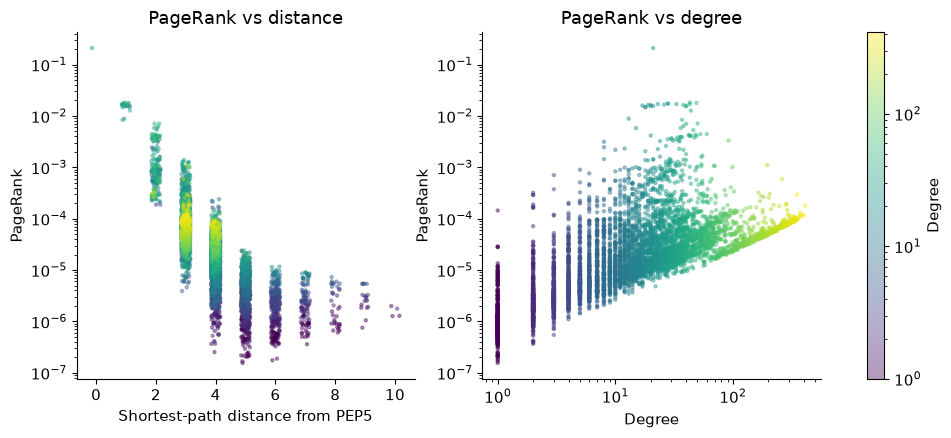

In [ ]:
nodes = [n for n in G if n in distances if n not in essential_proteins]

pr   = np.array([pagerank[n]  for n in nodes])
dist = np.array([distances[n] for n in nodes])
deg  = np.array([degrees[n]   for n in nodes])

rng = np.random.default_rng(1)
jitter = rng.uniform(-0.15, 0.15, size=len(nodes))

# sort ascending by degree so high-degree points are drawn last
order = np.argsort(deg, kind="stable")
pr, dist, deg, jitter = pr[order], dist[order], deg[order], jitter[order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(dist + jitter, pr, cmap="viridis", c=deg,
                norm=LogNorm(vmin=deg.min(), vmax=deg.max()), s=5, alpha=0.4)
axes[0].set_xlabel("Shortest-path distance from PEP5")
axes[0].set_ylabel("PageRank")
axes[0].set_yscale("log")
axes[0].set_title("PageRank vs distance")

sc = axes[1].scatter(deg, pr, cmap="viridis", c=deg,
                     norm=LogNorm(vmin=deg.min(), vmax=deg.max()), s=5, alpha=0.4)
axes[1].set_xlabel("Degree")
axes[1].set_ylabel("PageRank")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("PageRank vs degree")

fig.colorbar(sc, ax=axes, label="Degree")

plt.savefig("wk10/PPR.png")
plt.show()

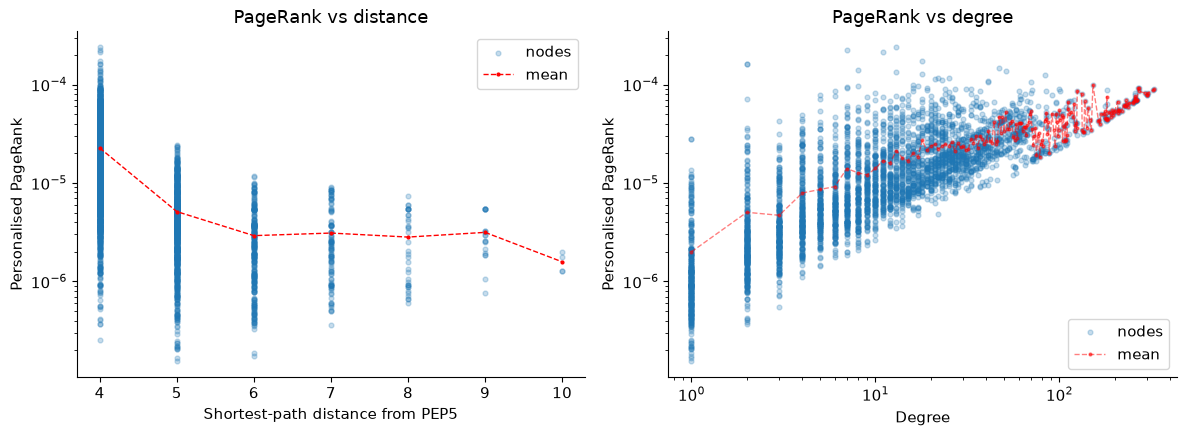

In [ ]:
df = pd.DataFrame({
    "pagerank": [pagerank[n] for n in nodes],
    "distance": [distances[n] for n in nodes],
    "degree":   [degrees[n] for n in nodes],
})

mean_by_dist = df.groupby("distance")["pagerank"].mean()
mean_by_deg  = df.groupby("degree")["pagerank"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# PageRank vs distance
axes[0].scatter(df["distance"], df["pagerank"], alpha=0.25, s=12, label="nodes")
axes[0].plot(mean_by_dist.index, mean_by_dist.values,
             "o--", color="red", lw=1, ms=2, label="mean")
axes[0].set_xlabel("Shortest-path distance from PEP5")
axes[0].set_ylabel("Personalised PageRank")
axes[0].set_yscale("log")
axes[0].set_title("PageRank vs distance")
axes[0].legend()

# PageRank vs degree
axes[1].scatter(df["degree"], df["pagerank"], alpha=0.25, s=12, label="nodes")
axes[1].plot(mean_by_deg.index, mean_by_deg.values,
             "o--", color="red", lw=1, ms=2, label="mean", alpha=0.5)
axes[1].set_xlabel("Degree")
axes[1].set_ylabel("Personalised PageRank")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("PageRank vs degree")
axes[1].legend()

plt.tight_layout()
plt.savefig("wk10/pagerank_stats.png")
plt.show()

I suppose we are interested in those nodes that have uncharacteristically high page rank given their degree and distance.

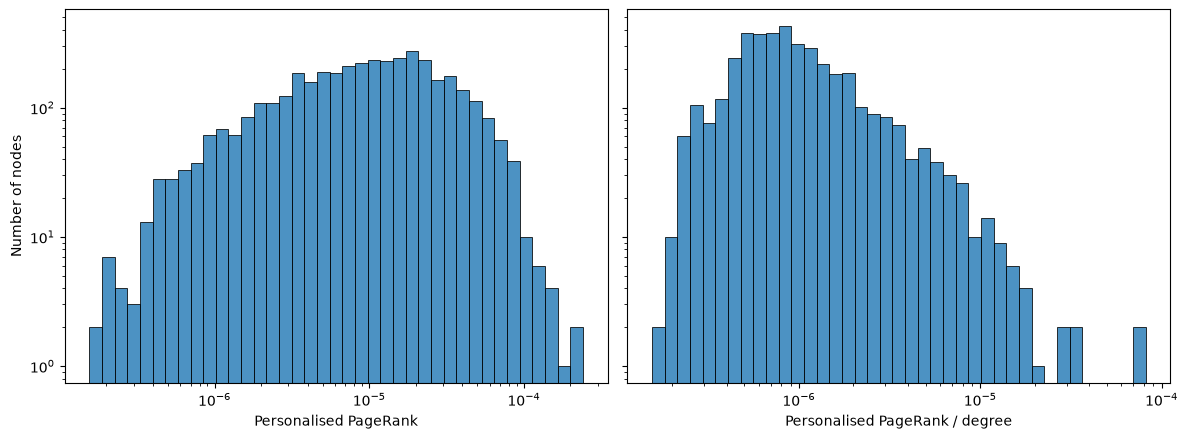

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Keep nodes with positive PageRank and nonzero degree so both arrays line up
nodes = [n for n in candidate_nodes if pagerank[n] > 0 and G.degree(n) > 0]

pr   = np.array([pagerank[n] for n in nodes])
pr_w = np.array([pagerank[n] / G.degree(n) for n in nodes])

def log_hist(ax, x, xlabel, color):
    bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 40)
    ax.hist(x, bins=bins, edgecolor="black", linewidth=0.7, alpha=0.8, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
log_hist(axes[0], pr,   "Personalised PageRank",           "tab:blue")
log_hist(axes[1], pr_w, "Personalised PageRank / degree",  "tab:blue")
axes[0].set_ylabel("Number of nodes")
plt.tight_layout()
plt.savefig("wk10/pagerank_histogram.png")
plt.show()

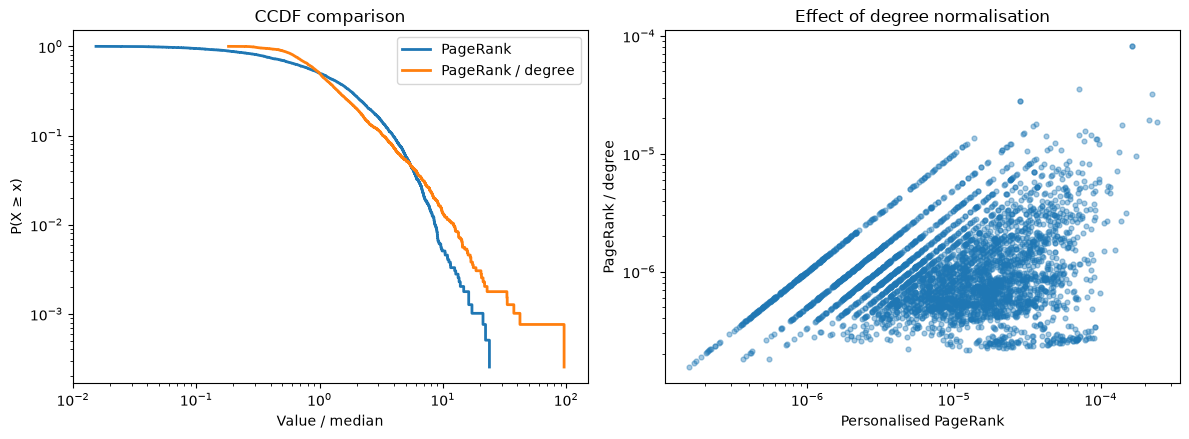

In [9]:
def ccdf(x):
    x = np.sort(x)
    return x, 1 - np.arange(len(x)) / len(x)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# CCDF overlay, rescaled by the median
for x, label in [(pr, "PageRank"), (pr_w, "PageRank / degree")]:
    xs, ys = ccdf(x / np.median(x))
    axes[0].step(xs, ys, where="post", label=label, lw=2)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Value / median")
axes[0].set_ylabel("P(X ≥ x)")
axes[0].set_title("CCDF comparison")
axes[0].legend()

# Scatter: how each node moves
axes[1].scatter(pr, pr_w, s=12, alpha=0.4)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Personalised PageRank")
axes[1].set_ylabel("PageRank / degree")
axes[1].set_title("Effect of degree normalisation")

plt.tight_layout()
plt.savefig("wk10/degree_normalisation.png")
plt.show()

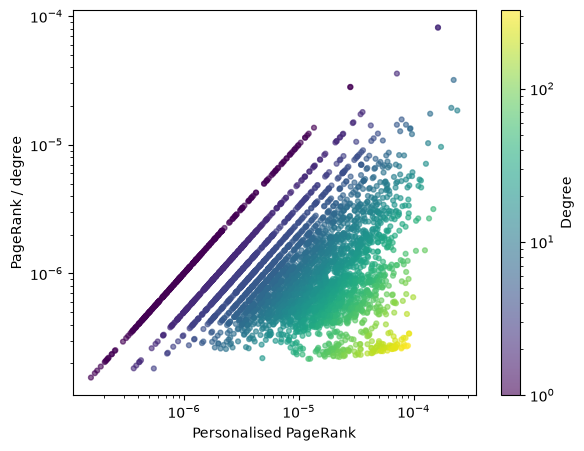

In [10]:
deg = np.array([G.degree(n) for n in nodes])

M = G.number_of_edges()
baseline = 1 / (2 * M)

fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(
    pr, pr_w,
    c=deg,                                   # raw degree, not log10
    cmap="viridis",
    norm=LogNorm(vmin=deg.min(), vmax=deg.max()),
    s=12, alpha=0.6,
)
  
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Personalised PageRank")
ax.set_ylabel("PageRank / degree")
plt.colorbar(sc, label="Degree")
plt.savefig("wk10/pagerank_degree_cmap.png")
plt.show()

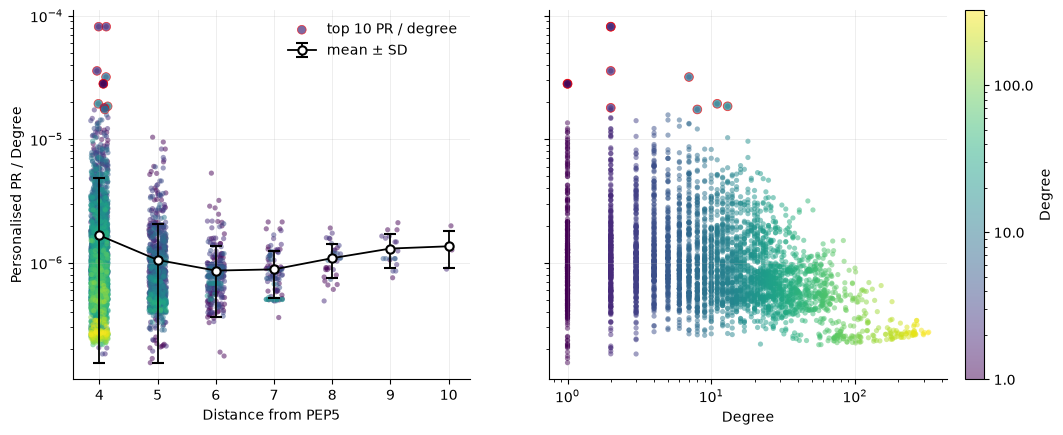

In [11]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter

# ---------- Data ----------
nodes = [n for n in candidate_nodes if n in distances]

df = pd.DataFrame({
    "node":        nodes,
    "distance":    [distances[n] for n in nodes],
    "degree":      [G.degree(n) for n in nodes],
    "weighted_PR": [pagerank[n] / G.degree(n) for n in nodes],
})

# Sort so hubs are drawn last; reset so the index is the row position
df = df.sort_values("degree").reset_index(drop=True)

top10 = df.nlargest(10, "weighted_PR")
top_idx = top10.index.to_numpy()

# Mean ± SD by distance, lower bar clipped for the log axis
floor = df["weighted_PR"].min()
grp = df.groupby("distance")["weighted_PR"]
stats_d = pd.DataFrame({"mean": grp.mean(), "sd": grp.std()}).dropna()
stats_d["lo"] = stats_d["mean"] - np.maximum(stats_d["mean"] - stats_d["sd"], floor)
stats_d["hi"] = stats_d["sd"]

# ---------- Plot setup ----------
cmap = "viridis"
norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())
rng = np.random.default_rng(1)
jitter = rng.uniform(-0.15, 0.15, size=len(df))

scatter_kw = dict(c=df["degree"], cmap=cmap, norm=norm, s=14, alpha=0.5, linewidths=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

# ---------- Left: by distance ----------
sc = axes[0].scatter(df["distance"] + jitter, df["weighted_PR"], zorder=1, **scatter_kw)
axes[0].scatter(top10["distance"] + jitter[top_idx], top10["weighted_PR"],
                c=top10["degree"], cmap=cmap, norm=norm,
                s=40, alpha=0.7, edgecolors="red", linewidths=0.5, zorder=4,
                label="top 10 PR / degree")
axes[0].errorbar(stats_d.index, stats_d["mean"],
                 yerr=[stats_d["lo"], stats_d["hi"]],
                 fmt="o-", color="black", lw=1.3, ms=6, mfc="white", mew=1.5,
                 capsize=4, capthick=1.5, label="mean ± SD", zorder=3)

axes[0].set_yscale("log")
axes[0].set_xticks(sorted(df["distance"].unique()))
axes[0].set_xlabel("Distance from PEP5")
axes[0].set_ylabel("Personalised PR / Degree")
axes[0].legend(frameon=False)

# ---------- Right: by degree ----------
axes[1].scatter(df["degree"], df["weighted_PR"], **scatter_kw)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Degree")
axes[1].scatter(top10["degree"], top10["weighted_PR"], c=top10["degree"],
                cmap=cmap, norm=norm, s=40, alpha=0.7,
                edgecolors="red", linewidths=0.6, zorder=4)

# ---------- Shared styling ----------
for ax in axes:
    ax.grid(True, which="major", alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=axes, pad=0.02, fraction=0.04, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/pr_by_distance_and_degree_top10.png", dpi=200, bbox_inches="tight")
plt.show()

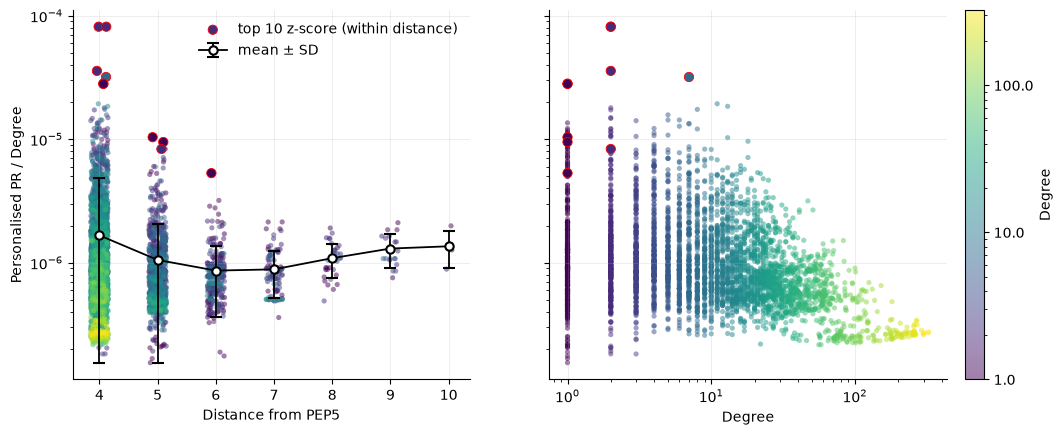

In [12]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter

# ---------- Data ----------
nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0]

df = pd.DataFrame({
    "node":        nodes,
    "distance":    [distances[n] for n in nodes],
    "degree":      [G.degree(n) for n in nodes],
    "weighted_PR": [pagerank[n] / G.degree(n) for n in nodes],
})

# Sort so hubs are drawn last; reset so the index is the row position
df = df.sort_values("degree").reset_index(drop=True)

# Z-score within each distance group (log scale; use "weighted_PR" for raw)
df["logPR"] = np.log10(df["weighted_PR"])
g = df.groupby("distance")["logPR"]
df["z"] = (df["logPR"] - g.transform("mean")) / g.transform("std")

top10 = df.nlargest(10, "z")          # NaN z-scores are ignored
top_idx = top10.index.to_numpy()

# Mean ± SD by distance, lower bar clipped for the log axis
floor = df["weighted_PR"].min()
grp = df.groupby("distance")["weighted_PR"]
stats_d = pd.DataFrame({"mean": grp.mean(), "sd": grp.std()}).dropna()
stats_d["lo"] = stats_d["mean"] - np.maximum(stats_d["mean"] - stats_d["sd"], floor)
stats_d["hi"] = stats_d["sd"]

# ---------- Plot setup ----------
cmap = "viridis"
norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())
rng = np.random.default_rng(1)
jitter = rng.uniform(-0.15, 0.15, size=len(df))

scatter_kw = dict(c=df["degree"], cmap=cmap, norm=norm, s=14, alpha=0.5, linewidths=0)
top_kw = dict(cmap=cmap, norm=norm, s=45, alpha=1,
              edgecolors="red", linewidths=0.6, zorder=4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

# ---------- Left: by distance ----------
sc = axes[0].scatter(df["distance"] + jitter, df["weighted_PR"], zorder=1, **scatter_kw)
axes[0].scatter(top10["distance"] + jitter[top_idx], top10["weighted_PR"],
                c=top10["degree"], label="top 10 z-score (within distance)", **top_kw)
axes[0].errorbar(stats_d.index, stats_d["mean"],
                 yerr=[stats_d["lo"], stats_d["hi"]],
                 fmt="o-", color="black", lw=1.3, ms=6, mfc="white", mew=1.5,
                 capsize=4, capthick=1.5, label="mean ± SD", zorder=3)

axes[0].set_yscale("log")
axes[0].set_xticks(sorted(df["distance"].unique()))
axes[0].set_xlabel("Distance from PEP5")
axes[0].set_ylabel("Personalised PR / Degree")
axes[0].legend(frameon=False)

# ---------- Right: by degree ----------
axes[1].scatter(df["degree"], df["weighted_PR"], zorder=1, **scatter_kw)
axes[1].scatter(top10["degree"], top10["weighted_PR"], c=top10["degree"], **top_kw)

axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Degree")

# ---------- Shared styling ----------
for ax in axes:
    ax.grid(True, which="major", alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=axes, pad=0.02, fraction=0.04, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/pr_by_distance_and_degree_zscore.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
print(top10)

           node  distance  degree  weighted_PR     logPR         z
479     YKL047W         4       2     0.000082 -4.088248  5.050616
480     YPL199C         4       2     0.000082 -4.088248  5.050616
81    YML094C-A         6       1     0.000005 -5.274417  4.357976
579     YMR282C         4       2     0.000036 -4.446159  4.099705
66      YDR524C         5       1     0.000010 -4.983350  4.011539
1501    YGL223C         4       7     0.000032 -4.495754  3.967940
86      YOR044W         5       1     0.000010 -5.022259  3.869306
122     YBR129C         4       1     0.000028 -4.549481  3.825194
25      YCL048W         4       1     0.000028 -4.551897  3.818776
512   YML007C-A         5       2     0.000008 -5.078891  3.662289


In [14]:
mg = mygene.MyGeneInfo()
print(mg.getgene('YKL047W'))
print(mg.getgene('YPL199C'))

{'AllianceGenome': 'SGD:S000001530', 'FungiDB': 'YKL047W', 'SGD': 'S000001530', 'VEuPathDB': 'YKL047W', '_id': '853819', '_version': 1, 'accession': {'genomic': ['BK006944.2', 'NC_001143.9'], 'protein': ['DAA09110.1', 'NP_012877.1', 'P36090.1'], 'rna': 'NM_001179613.1', 'translation': {'protein': 'NP_012877.1', 'rna': 'NM_001179613.1'}}, 'agr': {'orthologs': [{'algorithmsmatch': '5', 'gene_id': '853819', 'isbestrevscore': True, 'isbestscore': True, 'ortholog_id': '556432', 'outofalgorithms': '9', 'symbol': 'dennd11', 'taxid': 7955}, {'algorithmsmatch': '5', 'gene_id': '853819', 'isbestrevscore': True, 'isbestscore': True, 'ortholog_id': '57189', 'outofalgorithms': '9', 'symbol': 'DENND11', 'taxid': 9606}, {'algorithmsmatch': '4', 'gene_id': '853819', 'isbestrevscore': True, 'isbestscore': True, 'ortholog_id': '312270', 'outofalgorithms': '9', 'symbol': 'Dennd11', 'taxid': 10116}, {'algorithmsmatch': '4', 'gene_id': '853819', 'isbestrevscore': True, 'isbestscore': True, 'ortholog_id': '

This looks really promising, we are killing off any nodes with really high degree, but still seeing nodes of larger degree in our top selection.

Another approach might be just to compare to global page-rank.

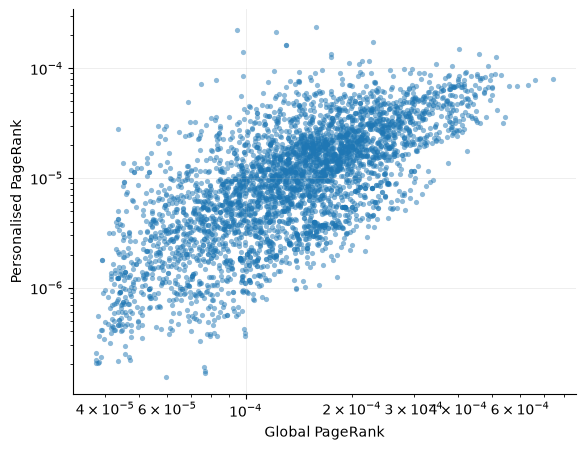

In [15]:
pr_global = nx.pagerank(G, alpha=ALPHA)  # same alpha as personalised run
nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":            nodes,
    "personalised_PR": [pagerank[n] for n in nodes],
    "distance":        [distances[n] for n in nodes],
    "degree":          [G.degree(n) for n in nodes],
    "global":          [pr_global[n] for n in nodes],
    "enrichment":      [pagerank[n] / pr_global[n] for n in nodes],
})

fig, ax = plt.subplots(figsize=(6.5, 5))

ax.scatter(df["global"], df["personalised_PR"],
           color="tab:blue", s=14, alpha=0.5, linewidths=0)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Global PageRank")
ax.set_ylabel("Personalised PageRank")
# ax.legend(frameon=False)

ax.grid(True, which="major", alpha=0.25, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig("wk10/global_vs_personalised_pr.png", dpi=200, bbox_inches="tight")
plt.show()

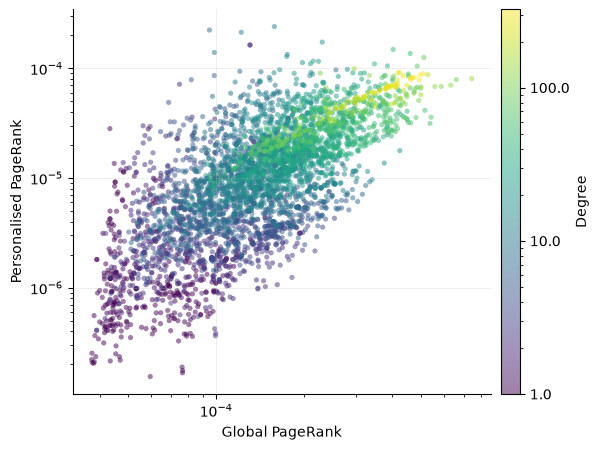

In [16]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

pr_global = nx.pagerank(G, alpha=ALPHA)  # same alpha as personalised run
nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":            nodes,
    "personalised_PR": [pagerank[n] for n in nodes],
    "distance":        [distances[n] for n in nodes],
    "degree":          [G.degree(n) for n in nodes],
    "global":          [pr_global[n] for n in nodes],
    "enrichment":      [pagerank[n] / pr_global[n] for n in nodes],
})

# Sort so hubs are drawn last
df = df.sort_values("degree").reset_index(drop=True)

norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())

fig, ax = plt.subplots(figsize=(6.5, 5))

sc = ax.scatter(df["global"], df["personalised_PR"],
                c=df["degree"], cmap="viridis", norm=norm,
                s=14, alpha=0.5, linewidths=0)

ax.set_xscale("log")
ax.set_yscale("log")

for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(LogLocator(base=10, numticks=6))
    axis.set_major_formatter(LogFormatterMathtext())
    axis.set_minor_formatter(NullFormatter())
    

ax.set_xlabel("Global PageRank")
ax.set_ylabel("Personalised PageRank")

ax.grid(True, which="major", alpha=0.25, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=ax, pad=0.02, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/global_vs_personalised_pr_degree.png", dpi=200, bbox_inches="tight")
plt.show()

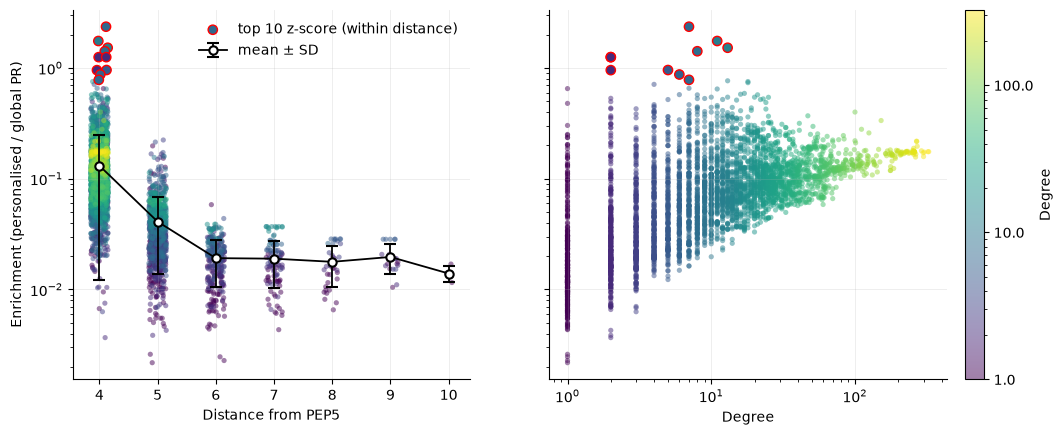

In [17]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter, LogLocator, LogFormatterMathtext, NullFormatter

# ---------- Data ----------
pr_global = nx.pagerank(G, alpha=ALPHA)

nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":            nodes,
    "personalised_PR": [pagerank[n] for n in nodes],
    "distance":        [distances[n] for n in nodes],
    "degree":          [G.degree(n) for n in nodes],
    "global":          [pr_global[n] for n in nodes],
    "enrichment":      [pagerank[n] / pr_global[n] for n in nodes],
})

# Sort so hubs are drawn last; reset so the index is the row position
df = df.sort_values("degree").reset_index(drop=True)

# ---------- Log-space statistics ----------
df["log_enrich"] = np.log10(df["enrichment"])
g = df.groupby("distance")["log_enrich"]

# Z-score of each node relative to others at the same distance
df["z"] = (df["log_enrich"] - g.transform("mean")) / g.transform("std")

top10 = df.nlargest(10, "z")          # NaN z-scores are ignored
top_idx = top10.index.to_numpy()

# Raw mean ± SD per distance; lower bar clipped at the data minimum for the log axis
floor = df["enrichment"].min()
grp = df.groupby("distance")["enrichment"]
stats_d = pd.DataFrame({"mean": grp.mean(), "sd": grp.std(), "n": grp.size()}).dropna()
stats_d["lo"] = stats_d["mean"] - np.maximum(stats_d["mean"] - stats_d["sd"], floor)
stats_d["hi"] = stats_d["sd"]

# ---------- Plot setup ----------
cmap = "viridis"
norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())
rng = np.random.default_rng(1)
jitter = rng.uniform(-0.15, 0.15, size=len(df))

scatter_kw = dict(c=df["degree"], cmap=cmap, norm=norm, s=14, alpha=0.5, linewidths=0)
top_kw = dict(cmap=cmap, norm=norm, s=45, alpha=1,
              edgecolors="red", linewidths=1.0, zorder=4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

# ---------- Left: by distance ----------
sc = axes[0].scatter(df["distance"] + jitter, df["enrichment"], zorder=1, **scatter_kw)
axes[0].scatter(top10["distance"] + jitter[top_idx], top10["enrichment"],
                c=top10["degree"], label="top 10 z-score (within distance)", **top_kw)
axes[0].errorbar(stats_d.index, stats_d["mean"],
                 yerr=[stats_d["lo"], stats_d["hi"]],
                 fmt="o-", color="black", lw=1.3, ms=6, mfc="white", mew=1.5,
                 capsize=4, capthick=1.5, label="mean ± SD", zorder=3)

axes[0].set_yscale("log")
axes[0].set_xticks(sorted(df["distance"].unique()))
axes[0].set_xlabel("Distance from PEP5")
axes[0].set_ylabel("Enrichment (personalised / global PR)")
axes[0].legend(frameon=False)

# ---------- Right: by degree ----------
axes[1].scatter(df["degree"], df["enrichment"], zorder=1, **scatter_kw)
axes[1].scatter(top10["degree"], top10["enrichment"], c=top10["degree"], **top_kw)

axes[1].set_xscale("log")
axes[1].set_xlabel("Degree")
axes[1].xaxis.set_major_locator(LogLocator(base=10, numticks=6))
axes[1].xaxis.set_major_formatter(LogFormatterMathtext())
axes[1].xaxis.set_minor_formatter(NullFormatter())

# ---------- Shared styling ----------
for ax in axes:
    ax.grid(True, which="major", alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=axes, pad=0.02, fraction=0.04, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/global_normalisation_zscore.png", dpi=200, bbox_inches="tight")
plt.show()

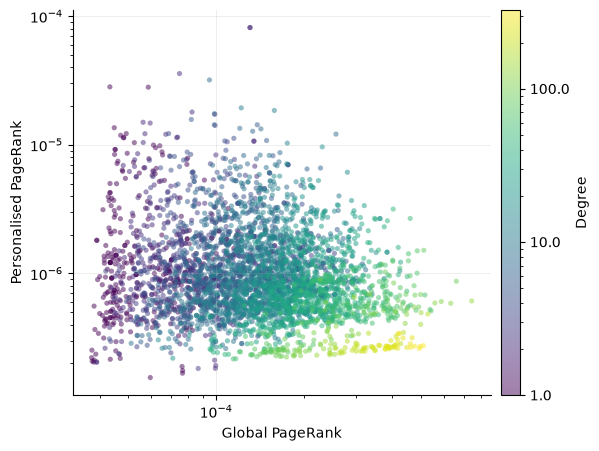

In [18]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

pr_global = nx.pagerank(G, alpha=ALPHA)  # same alpha as personalised run
nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":            nodes,
    "personalised_PR": [pagerank[n] for n in nodes],
    "distance":        [distances[n] for n in nodes],
    "degree":          [G.degree(n) for n in nodes],
    "global":          [pr_global[n] for n in nodes],
    "enrichment":      [pagerank[n] / pr_global[n] for n in nodes],
})

# Sort so hubs are drawn last
df = df.sort_values("degree").reset_index(drop=True)

norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())

fig, ax = plt.subplots(figsize=(6.5, 5))

sc = ax.scatter(df["global"], df["personalised_PR"]/df['degree'],
                c=df["degree"], cmap="viridis", norm=norm,
                s=14, alpha=0.5, linewidths=0)

ax.set_xscale("log")
ax.set_yscale("log")

for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(LogLocator(base=10, numticks=6))
    axis.set_major_formatter(LogFormatterMathtext())
    axis.set_minor_formatter(NullFormatter())
    

ax.set_xlabel("Global PageRank")
ax.set_ylabel("Personalised PageRank")

ax.grid(True, which="major", alpha=0.25, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=ax, pad=0.02, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/global_vs_personalised_pr_degree.png", dpi=200, bbox_inches="tight")
plt.show()

# Alpha analysis

         d=0     d=1     d=2     d=3     d=4     d=5    d>=6  E[walk length]
0.30  0.7029  0.2495  0.0413  0.0058  0.0004  0.0000  0.0000          0.4286
0.50  0.5068  0.3483  0.1101  0.0303  0.0043  0.0001  0.0000          1.0000
0.60  0.4086  0.3699  0.1537  0.0566  0.0107  0.0005  0.0000          1.5000
0.70  0.3099  0.3660  0.1993  0.0986  0.0248  0.0013  0.0001          2.3333
0.75  0.2602  0.3516  0.2205  0.1280  0.0374  0.0022  0.0002          3.0000
0.80  0.2100  0.3264  0.2379  0.1651  0.0565  0.0038  0.0003          4.0000
0.85  0.1593  0.2875  0.2475  0.2120  0.0866  0.0064  0.0006          5.6667
0.90  0.1079  0.2299  0.2406  0.2730  0.1362  0.0112  0.0013          9.0000
0.95  0.0552  0.1441  0.1954  0.3581  0.2243  0.0199  0.0031         19.0000
0.99  0.0114  0.0390  0.0840  0.4781  0.3504  0.0303  0.0069         99.0000


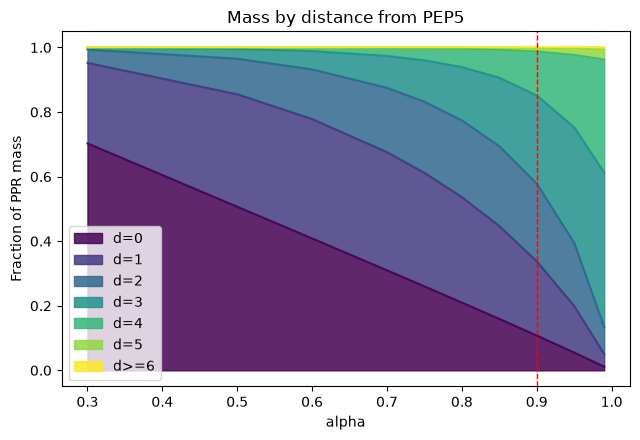

       TV distance to global PR  Spearman(PPR, degree)
alpha                                                 
0.30                      0.966                  0.595
0.50                      0.927                  0.609
0.60                      0.896                  0.623
0.70                      0.851                  0.645
0.75                      0.818                  0.661
0.80                      0.774                  0.684
0.85                      0.711                  0.715
0.90                      0.614                  0.762
0.95                      0.441                  0.841
0.99                      0.139                  0.958


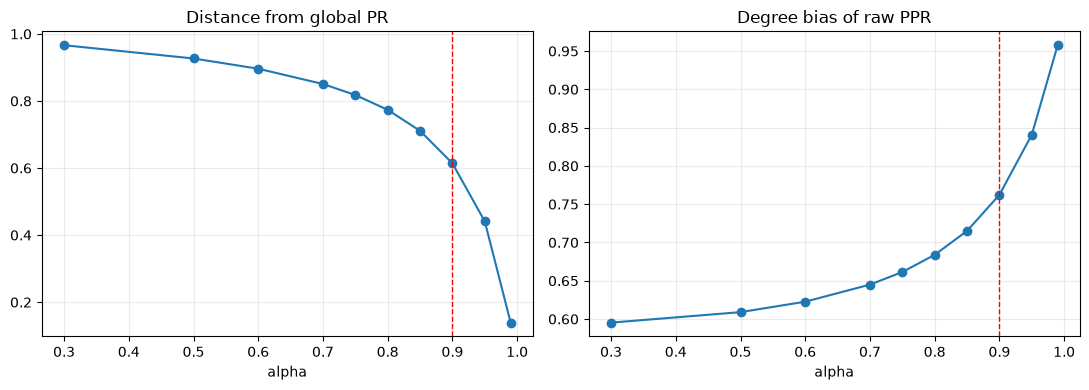

      top-k Jaccard vs ref  Spearman vs ref (all cands)
0.30                 0.538                        0.881
0.50                 0.667                        0.930
0.60                 0.667                        0.952
0.70                 0.667                        0.973
0.75                 0.667                        0.982
0.80                 0.818                        0.990
0.85                 0.818                        0.997
0.90                 1.000                        1.000
0.95                 0.818                        0.994
0.99                 0.538                        0.966

In top-25 for every alpha in 0.7-0.95: ['YBR129C', 'YCL048W', 'YCR067C', 'YDR124W', 'YDR141C', 'YDR524C', 'YGL161C', 'YGL199C', 'YGL223C', 'YKL047W', 'YML007C-A', 'YML094C-A', 'YMR282C', 'YOR044W', 'YOR216C', 'YPL085W', 'YPL199C', 'YPR097W']


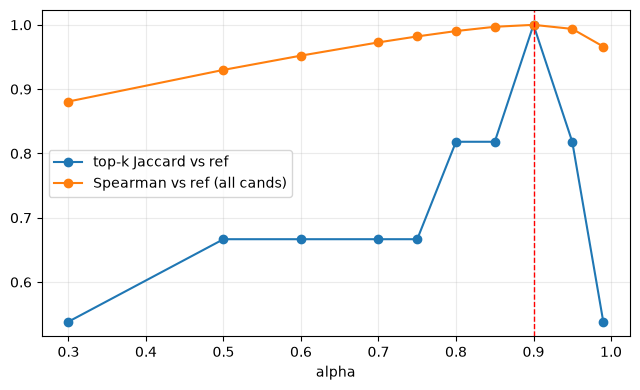

       good (mean pct rank)  exclude (mean pct rank)
alpha                                               
0.30                  0.910                    0.135
0.50                  0.909                    0.092
0.60                  0.908                    0.077
0.70                  0.907                    0.061
0.75                  0.906                    0.058
0.80                  0.902                    0.054
0.85                  0.901                    0.051
0.90                  0.899                    0.048
0.95                  0.898                    0.049
0.99                  0.896                    0.050
Fill in KNOWN (>=5 proteins) to run the leave-one-out validation.


In [19]:
# %% [markdown]
# # Choosing alpha for personalised PageRank
# Assumes these already exist from your notebook:
#   G, PEP5, distances, essential_proteins, candidate_nodes,
#   good_proteins, exclude_proteins
# Paste each cell (split on `# %%`) into the notebook, or run as a script.

# %% Setup
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ALPHAS = [0.3, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
REF_ALPHA = 0.9
TOP_K = 10
cand = list(candidate_nodes)


def ppr(alpha, seed=None):
    """Personalised PageRank. `seed` is a node or a list of nodes (uniform restart).
    Tight tol because far-away nodes carry mass ~1e-5 or less."""
    seed = PEP5 if seed is None else seed
    seeds = [seed] if not isinstance(seed, (list, set, tuple)) else list(seed)
    pers = {s: 1 / len(seeds) for s in seeds}
    return nx.pagerank(G, alpha=alpha, personalization=pers, tol=1e-12, max_iter=5000)


def candidate_scores(pr, nodes=cand, dist=distances):
    """Same ranking statistic as your z-score cell: z of log10(PR/degree) within distance."""
    df = pd.DataFrame({
        "node": nodes,
        "distance": [dist[n] for n in nodes],
        "val": [pr[n] / G.degree(n) for n in nodes],
    })
    df = df[df.val > 0]
    df["log"] = np.log10(df.val)
    g = df.groupby("distance")["log"]
    df["z"] = (df.log - g.transform("mean")) / g.transform("std")
    return df.set_index("node")["z"]


runs = {a: ppr(a) for a in ALPHAS}
scores = pd.DataFrame({a: candidate_scores(runs[a]) for a in ALPHAS})

# %% 1. Where does the walk put its mass? (locality)
# Fraction of PPR mass at each distance from PEP5, plus mean walk length.
dist_all = nx.single_source_shortest_path_length(G, PEP5)
max_d = 6
rows = []
for a in ALPHAS:
    m = np.zeros(max_d + 1)
    for n, p in runs[a].items():
        m[min(dist_all[n], max_d)] += p
    rows.append(m)
mass = pd.DataFrame(rows, index=ALPHAS,
                    columns=[f"d={i}" if i < max_d else f"d>={max_d}" for i in range(max_d + 1)])
mass["E[walk length]"] = [a / (1 - a) for a in ALPHAS]
print(mass.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
mass.drop(columns="E[walk length]").plot.area(ax=ax, colormap="viridis", alpha=0.85)
ax.axvline(REF_ALPHA, color="red", ls="--", lw=1)
ax.set_xlabel("alpha"); ax.set_ylabel("Fraction of PPR mass")
ax.set_title("Mass by distance from PEP5")
plt.tight_layout(); plt.show()
# Read it as: your targets live at d >= 4 (MIN_DISTANCE). Pick alpha so a
# meaningful share of mass reaches them, without most of it being "background".

# %% 2. Is the personalisation still there? (vs. global PageRank / degree)
deg_all = pd.Series(dict(G.degree()))
rows = []
for a in ALPHAS:
    p = pd.Series(runs[a])
    g = pd.Series(nx.pagerank(G, alpha=a, tol=1e-12, max_iter=5000))
    idx = p.index
    rows.append({
        "alpha": a,
        "TV distance to global PR": 0.5 * (p[idx] - g[idx]).abs().sum(),
        "Spearman(PPR, degree)": spearmanr(p[idx], deg_all[idx])[0],
    })
pers = pd.DataFrame(rows).set_index("alpha")
print(pers.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
pers["TV distance to global PR"].plot(ax=ax[0], marker="o"); ax[0].set_title("Distance from global PR")
pers["Spearman(PPR, degree)"].plot(ax=ax[1], marker="o"); ax[1].set_title("Degree bias of raw PPR")
for x in ax:
    x.axvline(REF_ALPHA, color="red", ls="--", lw=1); x.grid(alpha=0.25)
plt.tight_layout(); plt.show()
# As alpha -> 1, TV -> 0 and PPR -> degree: you lose exactly the signal you want.

# %% 3. Robustness of YOUR conclusion: does the top-k list depend on alpha?
def topk(a, k=TOP_K):
    return set(scores[a].dropna().nlargest(k).index)

ref = topk(REF_ALPHA)
robust = pd.DataFrame({
    "top-k Jaccard vs ref": [len(topk(a) & ref) / len(topk(a) | ref) for a in ALPHAS],
    "Spearman vs ref (all cands)": [scores[[a, REF_ALPHA]].dropna().corr(method="spearman").iloc[0, 1]
                                    for a in ALPHAS],
}, index=ALPHAS)
print(robust.round(3))

# Which nodes survive across the whole sensible range?
rng = [a for a in ALPHAS if 0.7 <= a <= 0.95]
survivors = set.intersection(*[topk(a, 25) for a in rng])
print(f"\nIn top-25 for every alpha in {rng[0]}-{rng[-1]}:", sorted(survivors))

fig, ax = plt.subplots(figsize=(6.5, 4))
robust.plot(ax=ax, marker="o")
ax.axvline(REF_ALPHA, color="red", ls="--", lw=1); ax.set_xlabel("alpha"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()
# A flat plateau around 0.85 is the cleanest justification: "results insensitive to alpha".

# %% 4a. Use your own labels: good_proteins vs exclude_proteins
rows = []
for a in ALPHAS:
    pct = scores[a].rank(pct=True)          # 1.0 = best
    rows.append({
        "alpha": a,
        "good (mean pct rank)": pct.reindex(good_proteins).mean(),
        "exclude (mean pct rank)": pct.reindex(exclude_proteins).mean(),
    })
lab = pd.DataFrame(rows).set_index("alpha")
print(lab.round(3))
# You want good high, exclude low. With only 6 proteins treat this as a sanity
# check, not as evidence.

# %% 4b. Held-out validation (the strongest argument)
# Idea: take proteins you believe belong to PEP5's functional neighbourhood
# (HOPS/CORVET complexes, GO "vacuole fusion"/"vacuolar transport", etc.).
# Leave one out, seed on the rest, see where the held-out protein ranks.
# Pick alpha that recovers held-out members best, ideally a plateau.
#
# Fill this in; get IDs from GO/SGD/YeastMine. Don't include proteins that are
# your discovery candidates, or the validation becomes circular.
KNOWN = []   # e.g. ["YMR231W", "YLR148W", ...]  (must be nodes in G)

def loo_eval(known, alphas=ALPHAS):
    known = [k for k in known if k in G]
    out = {a: {"AUC raw": [], "AUC PR/deg": []} for a in alphas}
    for a in alphas:
        for held in known:
            seeds = [k for k in known if k != held]
            p = pd.Series(ppr(a, seed=seeds))
            pool = p.drop(seeds)                      # everything except the seeds
            for name, s in [("AUC raw", pool),
                            ("AUC PR/deg", pool / deg_all[pool.index])]:
                out[a][name].append(s.rank(pct=True)[held])   # percentile rank == per-protein AUC
    return pd.DataFrame({a: {k: np.mean(v) for k, v in d.items()} for a, d in out.items()}).T

if len(KNOWN) >= 5:
    loo = loo_eval(KNOWN)
    print(loo.round(3))
    loo.plot(marker="o"); plt.axvline(REF_ALPHA, color="red", ls="--", lw=1)
    plt.xlabel("alpha"); plt.ylabel("Mean percentile rank of held-out protein"); plt.grid(alpha=0.25)
    plt.show()
else:
    print("Fill in KNOWN (>=5 proteins) to run the leave-one-out validation.")

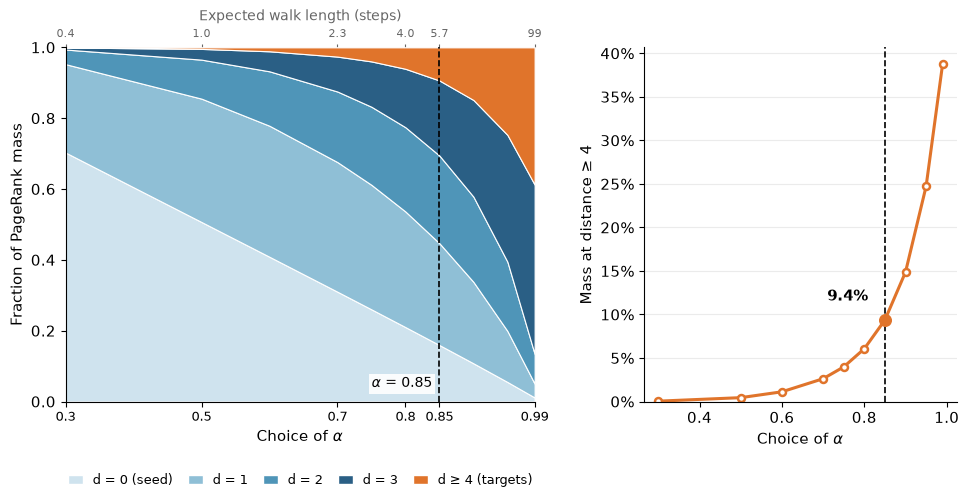

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_mass_by_distance(mass, ref_alpha=0.85, min_distance=4,
                          path="wk10/mass_by_distance.png"):
    """Report-ready figure from the `mass` table (index = alpha, columns d=0.. d>=6)."""
    dcols = [c for c in mass.columns if c.startswith("d")]
    near = [c for c in dcols if int(c.replace("d=", "").replace("d>=", "")) < min_distance]
    far = [c for c in dcols if c not in near]

    m = mass[near].copy()
    m[f"d \u2265 {min_distance}"] = mass[far].sum(axis=1)
    alphas = m.index.to_numpy()
    ref_i = int(np.argmin(np.abs(alphas - ref_alpha)))

    # cool, light-to-dark for near-seed bands; one warm colour for the target band
    colors = ["#cfe3ee", "#8fbfd6", "#4f95b8", "#2a5f85", "#e0742b"]
    labels = ["d = 0 (seed)", "d = 1", "d = 2", "d = 3", f"d \u2265 {min_distance} (targets)"]

    plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                         "axes.spines.right": False})
    fig, (ax, ax2) = plt.subplots(
        1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.28})

    # ---- (a) stacked mass by distance ----
    ax.stackplot(alphas, m.T.values, colors=colors, edgecolor="white", linewidth=0.8)
    ax.set_xlim(alphas.min(), alphas.max()); ax.set_ylim(0, 1)
    ticks = sorted({a for a in alphas if a in (0.3, 0.5, 0.7, 0.8, 0.99)} | {alphas[ref_i]})
    ax.set_xticks(ticks); ax.set_xticklabels([f"{a:g}" for a in ticks], fontsize=9)
    ax.set_xlabel(r"Choice of $\alpha$"); ax.set_ylabel("Fraction of PageRank mass")

    handles = [plt.Rectangle((0, 0), 1, 1, fc=c, ec="white") for c in colors]
    ax.legend(handles, labels, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.17),
              frameon=False, fontsize=9, handlelength=1.2, columnspacing=1.2)

    # reference alpha
    ax.axvline(alphas[ref_i], color="black", ls="--", lw=1.2)
    ax.text(alphas[ref_i] - 0.01, 0.03, rf"$\alpha$ = {alphas[ref_i]:g}", ha="right", va="bottom",
            fontsize=10, bbox=dict(fc="white", ec="none", pad=2, alpha=0.9))

    # walk length on a top axis
    sec = ax.secondary_xaxis("top")
    sec.set_xticks(ticks)
    sec.set_xticklabels([f"{a/(1-a):.1f}" if a/(1-a) < 10 else f"{a/(1-a):.0f}" for a in ticks],
                        fontsize=8, color="0.4")
    sec.tick_params(length=2, colors="0.4")
    sec.spines["top"].set_visible(False)
    sec.set_xlabel("Expected walk length (steps)", fontsize=10, color="0.4", labelpad=6)

    # ---- (b) share reaching the target distances ----
    far_share = m[f"d \u2265 {min_distance}"].to_numpy()
    ax2.plot(alphas, far_share, "-o", color=colors[-1], lw=2.2, ms=5, mfc="white", mew=1.8)
    ax2.axvline(alphas[ref_i], color="black", ls="--", lw=1.2)
    ax2.scatter([alphas[ref_i]], [far_share[ref_i]], s=70, color=colors[-1], zorder=5)
    ax2.annotate(f"{far_share[ref_i]:.1%}", (alphas[ref_i], far_share[ref_i]),
                 xytext=(-12, 14), textcoords="offset points", ha="right", fontweight="bold")
    ax2.set_xlabel(r"Choice of $\alpha$")
    ax2.set_ylabel(f"Mass at distance \u2265 {min_distance}")
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax2.set_ylim(0, None); ax2.grid(axis="y", alpha=0.25)

    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    return fig

fig = plot_mass_by_distance(mass.drop(columns="E[walk length]"), ref_alpha=0.85)
plt.show()